# 04 · Revenue and usage
Questions 1, 2, 4, 5 and 18: where revenue comes from, how ARPU moves, and where usage is growing.

In [1]:
import sys, pathlib, json
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.data_loader import get_engine, query, PROJECT_ROOT
from src import analysis as an
an.set_style()
pd.set_option("display.float_format", "{:,.2f}".format); pd.set_option("display.max_columns", 30)
engine = get_engine()
o = an.sql_output

In [2]:
o('q01_headline_kpis').T

,0
month,2026-10-01
opening_base,20186
active_customers,19182
new_customers,434
churned,280
revenue,"17,926,225.00"
arpu,934.53
churn_rate_pct,1.39
revenue_yoy_pct,19.27
arpu_yoy_pct,7.64


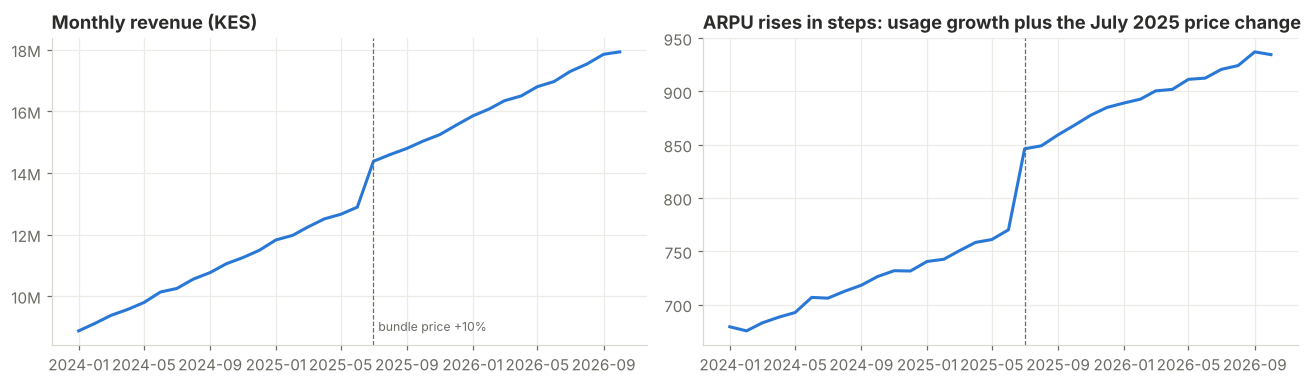

In [3]:
k = o("q02_monthly_kpi_trend"); k["month"] = pd.to_datetime(k.month)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(k.month, k.revenue, color=an.PRIMARY); an.kes_axis(ax[0]); ax[0].set_title("Monthly revenue (KES)")
ax[0].axvline(pd.Timestamp("2025-07-01"), color=an.INK_MUTED, ls="--", lw=.8); ax[0].text(pd.Timestamp("2025-07-10"), k.revenue.min(), "bundle price +10%", fontsize=8, color=an.INK_MUTED)
ax[1].plot(k.month, k.arpu, color=an.PRIMARY, label="ARPU (KES per active customer)")
ax[1].set_title("ARPU rises in steps: usage growth plus the July 2025 price change")
ax[1].axvline(pd.Timestamp("2025-07-01"), color=an.INK_MUTED, ls="--", lw=.8)
fig.tight_layout(); an.save(fig, "revenue_and_arpu_trend");

In [4]:
o('q03_revenue_by_service')

,service_type,revenue_kes,revenue_share_pct,transactions,avg_ticket_kes,yoy_growth_pct
0,Postpaid Bill,"153,044,860.00",33.64,77182,"1,983.00",36.66
1,Data Bundle,"119,731,073.00",26.31,467178,256.00,26.31
2,Combo Bundle,"75,200,601.00",16.53,302614,249.00,25.77
3,Voice Bundle,"62,372,890.00",13.71,288631,216.00,24.87
4,Mobile Money Fees,"29,825,181.00",6.56,557074,54.00,12.50
5,SMS Bundle,"14,822,782.00",3.26,74346,199.00,24.52


Postpaid bills are a third of revenue from about 12% of customers. Among prepaid services, **data bundles are the largest and among the fastest growing**. Mobile-money fees grew least: they're a small, fee-based line that depends on transaction counts rather than bundle prices.

In [5]:
g = o("q04_value_by_customer_group")
g[g.dim.isin(["customer_type", "plan_type", "age_group"])]

,dim,grp,customers,revenue_kes,revenue_share_pct,arpu_kes
0,age_group,25-34,8170,"136,424,251.00",29.98,846.00
1,age_group,35-44,6258,"117,625,863.00",25.85,946.00
2,age_group,18-24,6450,"84,133,274.00",18.49,682.00
3,age_group,45-54,4594,"77,124,512.00",16.95,835.00
4,age_group,55+,3024,"39,689,487.00",8.72,673.00
18,customer_type,Prepaid,25093,"297,600,403.00",65.41,616.00
19,customer_type,Postpaid,3403,"157,396,984.00",34.59,"2,039.00"
20,plan_type,Prepaid Flex,15233,"153,305,221.00",33.69,541.00
21,plan_type,Prepaid Data Plus,9860,"144,295,182.00",31.71,722.00
22,plan_type,Postpaid Business,2059,"140,552,679.00",30.89,"2,878.00"


,tenure_band,customers,active_customer_months,arpu_kes,avg_data_mb,monthly_churn_pct
0,a) 0-2 months,15943,43956,681.00,"3,666.00",0.00
1,b) 3-5 months,15250,38572,787.00,"4,409.00",2.20
2,c) 6-11 months,14292,65340,818.00,"4,556.00",2.32
3,d) 12-23 months,12726,98069,850.00,"4,728.00",1.69
4,e) 24-47 months,12430,145014,814.00,"4,393.00",1.11
5,f) 48+ months,8957,169478,825.00,"4,564.00",1.11


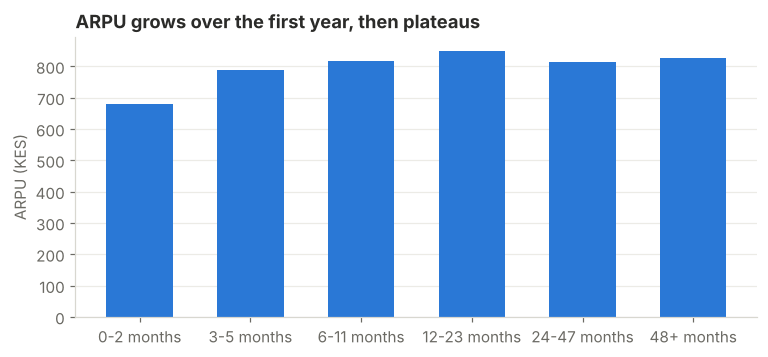

In [6]:
t = o("q06_value_by_tenure")
fig, ax = plt.subplots(figsize=(8, 3.3))
ax.bar(t.tenure_band.str[3:], t.arpu_kes, color=an.PRIMARY, width=.6); ax.set_ylabel("ARPU (KES)")
ax.set_title("ARPU grows over the first year, then plateaus"); ax.grid(axis="x", visible=False)
an.save(fig, "arpu_by_tenure"); t

In [7]:
o('q24_usage_growth')

,period,avg_data_mb,avg_voice_minutes,avg_sms,arpu_kes
0,Year 1 (Nov24-Oct25),"4,245.00",213.00,36.30,786.00
1,Year 2 (Nov25-Oct26),"5,312.00",208.00,32.80,908.00


**Growth signal:** data per active customer rose by about a quarter year-on-year, while voice and SMS per customer are flat to falling. Data is where engagement is growing, and voice and SMS are mature. This is the growth opportunity behind question 18.